In [1]:
import magnumnp as mp
import torch
import numpy as np 
import matplotlib.pyplot as plt 
from tqdm import tqdm 
from scripts.read_field import field_image
from scripts.scientific import apply

2026-11-11 12:25:06  magnum.np:INFO magnum.np 2.2.0 (/Users/nazarsi/Library/Python/3.13/lib/python/site-packages/ipykernel_launcher.py --f=/Users/nazarsi/Library/Jupyter/runtime/kernel-v32d887f025b59a8f3f0985aee1f95a48099523e72.json)


In [2]:
device = torch.device('mps')
torch.set_default_device(device)
torch.set_default_dtype(torch.float32)


In [33]:
class PearlVortex:
    def __init__(
        self, state: mp.State,
        pos=(0.0, 0.0),
        lambdaP=200e-9,
        phi0=2.067833848e-15,
        core_radius=2.5e-9,
        sigma=1.0,
        df = 2.5e-9
    ):
        # Позиция и параметры вихря
        self.pos = torch.tensor(pos, dtype=state.m.dtype, device=state.m.device)
        self.lambdaP = torch.tensor(lambdaP, dtype=state.m.dtype, device=state.m.device)
        self.phi0 = torch.tensor(phi0, dtype=state.m.dtype, device=state.m.device)
        self.core_radius = torch.tensor(core_radius, dtype=state.m.dtype, device=state.m.device)
        self.sigma = torch.tensor(sigma, dtype=state.m.dtype, device=state.m.device)
        self.df = torch.tensor(df, dtype=state.m.dtype, device=state.m.device)

    def B(self, state, pos=None):
        if pos is None:
            pos = self.pos

        X, Y, _ = state.mesh.SpatialCoordinate()

        dx = X - pos[0]
        dy = Y - pos[1]

        r = torch.sqrt(dx**2 + dy**2)

        Br = self.interpolate_profile(r, self.Br_profile)
        Bz = self.interpolate_profile(r, self.Bz_profile)

        # Radial direction; handle r = 0.
        r_safe = torch.sqrt(r ** 2 + self.core_radius ** 2) 

        Bx = Br * dx / r_safe
        By = Br * dy / r_safe

        return torch.stack(
            (Bx, By, Bz), dim=-1
        )

    def build_profile(self, state, r_max, Nr=8193, Nq=1024):

        device = state.m.device
        dtype = state.m.dtype

        q_max = 50.0 / self.lambdaP

        q = torch.linspace(
            0.0, q_max, Nq,
            dtype=torch.float64,
            device="cpu",
        )

        rho = torch.linspace(
            0.0, r_max, Nr,
            dtype=torch.float64,
            device="cpu",
        )

        qr = q[:, None] * rho[None, :]

        exp_term = torch.exp(-q * self.df.cpu())
        denom = 1.0 + 2.0 * q * self.lambdaP.cpu()

        common = q * exp_term / denom

        J0 = torch.special.bessel_j0(qr)
        J1 = torch.special.bessel_j1(qr)

        integrand_r = common[:, None] * J1
        integrand_z = common[:, None] * J0

        prefactor = self.phi0.cpu() / (2.0 * torch.pi)

        Br = prefactor * torch.trapezoid(integrand_r, q, dim=0)
        Bz = prefactor * torch.trapezoid(integrand_z, q, dim=0)

        self.r_max = float(r_max)
        self.Nr = Nr
        self.dr = self.r_max / (Nr - 1)

        self.Br_profile = Br.to(device=device, dtype=dtype)
        self.Bz_profile = Bz.to(device=device, dtype=dtype)

    def interpolate_profile(self, r, profile):
        """
        Linear interpolation on a uniformly spaced radial grid.

        The grid index is nondifferentiable, but the interpolation
        coefficient remains differentiable with respect to r.
        """

        u = (r / self.dr).clamp(0.0, self.Nr - 1 - 1e-6)

        i0 = torch.floor(u).long()
        t = u - i0.to(dtype=u.dtype)

        return (
            (1.0 - t) * profile[i0]
            + t * profile[i0 + 1]
        )

    def H(self, state: mp.State):
        """Поле H = B/μ0 в A/м для ExternalField."""
        return self.B(state) / mp.constants.mu_0

    def interaction_energy(self, state: mp.State, pos):
        B = self.B(state, pos)
        m_dot_B = (state.m * B).sum(dim=-1, keepdim=True)  # форма (...,1)
        # Энергия плотности = -Ms * (m·B)
        density = -state.material["Ms"] * m_dot_B
        return (density * state.mesh.cell_volumes).sum()

    def velocity(self, state: mp.State):
        """
        Уравнение движения вихря: sigma * dpos/dt = -grad_pos F_interaction.
        """
        pos = self.pos.detach().clone().requires_grad_(True)
        F = self.interaction_energy(state, pos)
        gradF = torch.autograd.grad(F, pos)[0]
        return -gradF / self.sigma

    def advance(self, state: mp.State, dt):
        """Явный метод Эйлера для обновления положения вихря."""
        v = self.velocity(state)
        self.pos = (self.pos + v * dt).detach()
        return v


In [52]:
mp.Timer.enable()

L = 7e-7
lw = 1e-7
dx = (2.5e-9, 2.5e-9, 2.5e-9)
n = (int(2 * L / dx[0]) + 1, int(2 * L /  dx[1]) + 1, 1)
origin = (-L, -L, 0)
mesh = mp.Mesh(n, dx, origin)

state = mp.State(mesh)
Ms0 = 1e5
K0 = 1000.0

gamma = 0.15
phi0 = 2.067833848e-15

lambdaP = float(np.sqrt(
    Ms0 * phi0 / (2 * np.pi * K0 * gamma)
))
state.material = {
    "Ms": Ms0,
    "A": 1e-11,
    "Ku": K0,
    "Ku_axis": (0, 0, 1.0),
    "Di": 2 * 0.3 * 1e-4,
    "alpha": 0.1,
}
def e_dmi(state: mp.State):
    X, Y, _ = state.mesh.SpatialCoordinate()
    x_tip, y_tip = 2 * lw, 0
    D = 1e-4
    beta = 0
    epsilon = 0.45
    r2 = (X - x_tip) ** 2 + (Y - y_tip) ** 2
    return 2 * D * (epsilon + beta * lw ** 3 / (r2 + lw ** 2) ** 1.5)

state.material['Di'] = e_dmi(state)

def skyrmion(state: mp.State):
    X, Y, _ = state.mesh.SpatialCoordinate()
    R = 1 * lw
    w = 1 * lw
    r = torch.sqrt(X ** 2 + Y ** 2)
    theta = 2 * torch.arctan(np.sinh(R / w) / torch.sinh(r / w))
    phi = torch.atan2(Y, X)
    mx = torch.sin(theta) * torch.cos(phi)
    my = torch.sin(theta) * torch.sin(phi)
    mz = torch.cos(theta)
    return torch.stack([mx, my, mz], dim=-1)

state.m = skyrmion(state)

vortex = PearlVortex(
    state,
    pos=(0.5 * lw, 0.5 * lw),
    lambdaP=lambdaP,
    phi0=phi0,
    core_radius=3 * dx[0],
    sigma=1e-15,
)

vortex.build_profile(
    state,
    r_max=2 * np.sqrt(2) * L,
    Nr=8193,
    Nq=1024,
)
vortex_field = mp.ExternalField(
    lambda state: vortex.H(state)
)

exchange = mp.ExchangeField()
anisotropy = mp.UniaxialAnisotropyField()
dmi = mp.InterfaceDMIField()

llg = mp.LLGSolver([
    exchange,
    anisotropy,
    dmi,
    vortex_field,
])

states = [state.m.clone().detach().cpu().reshape((n[0], n[1], 3)).swapaxes(0,1)]
vortex_positions = [vortex.pos.cpu().numpy().copy()]

dt = 1e-11
for i in tqdm(range(101)):
    vortex.advance(state, dt / 2)
    llg.step(state, dt)
    vortex.advance(state, dt / 2)

    states.append(state.m.clone().detach().cpu().reshape((n[0], n[1], 3)).swapaxes(0,1))
    vortex_positions.append(vortex.pos.cpu().numpy().copy())

2026-11-11 12:55:17  magnum.np:INFO [State] running on device: mps:0 (dtype = float32)
2026-11-11 12:55:17  magnum.np:INFO [Mesh] 561x561x1 (dx= 2.5e-09 x 2.5e-09 x 2.5e-09)
2026-11-11 12:55:17  magnum.np:INFO [LLGSolver] using RKF45 solver (atol = 1e-05)
 27%|██▋       | 27/101 [01:05<02:58,  2.41s/it]


KeyboardInterrupt: 

0
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
0


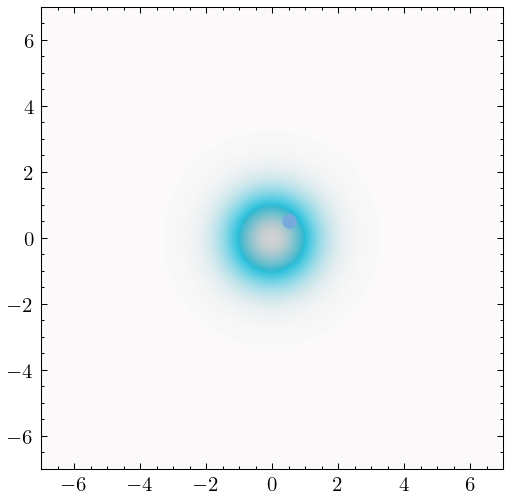

In [54]:
from matplotlib import animation
from matplotlib.patches import Circle
from cmap import Colormap, Color

name = 'test_magnum'

_cmap = Colormap('colorcet:cet_cbtc2').to_mpl()
_cmap2 = Colormap('colorbrewer:YlGn_3').to_mpl()
cmap = Colormap([_cmap(0), _cmap(0), _cmap2(0.5), _cmap(0.5), _cmap2(1), _cmap(1)]).to_mpl()

fig, ax = plt.subplots()
def update(i):
    print(i)
    ax.clear()
    m = states[i].numpy()
    # B = vortex_field([mesh[0].cpu(), mesh[1].cpu()], state.cpu(), frames[i]).cpu().numpy()
    # t = (((1 - m[:,:,2]) / 2))[...,None]
    image_skyrmion = np.clip(field_image(m, color='spirality'), 0,1)
    # image_vortex = cmap(np.linalg.norm(B, axis=2))
    ax.imshow(image_skyrmion[::-1], extent=[-L / lw, L / lw, -L / lw, L / lw])
    plt.scatter(vortex_positions[i][0] / lw, vortex_positions[i][1] / lw)
ani = animation.FuncAnimation(fig, update, repeat=True, frames=len(states), interval=50)
writer = animation.FFMpegWriter(fps=25)
ani.save(f"./thiele_tensor/{name}.mp4", writer=writer, dpi=200)